# SiPM edge-setup comparison

This notebook compares every completed `sipm_timing_edge*_analysis` folder found under `BASE_DIR`. It currently covers edge0–edge2 and will include edge3 automatically after its analysis CSVs appear.

The comparison focuses on: signal yield and efficiency, first-photon timing, effective SiPM geometry, and position-reconstruction resolution. Lower is better for all resolution metrics.

In [52]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    # 'axes.spines.top': False,
    # 'axes.spines.right': False,
    'axes.titleweight': 'bold',
})
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

## 1. Configuration and discovery

Only change `BASE_DIR` if the study moves. `EXPORT_DIR = None` keeps the notebook read-only; set it to a directory if you want saved copies of generated figures.

In [ ]:
LENGTH = 200  # detector size [mm]
BASE_DIR = Path(f'/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_{LENGTH}')
EXPORT_DIR = Path(f'/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_{LENGTH}/edge_comparison_figures')  # Example: Path(f'./edge_comparison_figures_{LENGTH}')
REQUIRED_CSVS = (
    'sipm_signal_summary.csv',
    'sipm_effective_positions.csv',
    'position_resolution_summary.csv',
)

def edge_number(path):
    match = re.search(r'edge(\d+)_{LENGTH}_analysis$', path.name)
    return int(match.group(1)) if match else None

candidates = sorted(
    (p for p in BASE_DIR.glob(f'output_edge*_{LENGTH}_analysis') if edge_number(p) is not None),
    key=edge_number,
)
status_rows = []
for folder in candidates:
    missing = [name for name in REQUIRED_CSVS if not (folder / name).exists()]
    status_rows.append({
        'setup': f'edge{edge_number(folder)}',
        'folder': str(folder),
        'status': 'ready' if not missing else 'incomplete',
        'missing': ', '.join(missing),
    })

status = pd.DataFrame(status_rows)
if status.empty:
    raise FileNotFoundError(f'No edge analysis folders found below {BASE_DIR}')
display(status)

analysis_dirs = [
    Path(row.folder) for row in status.itertuples() if row.status == 'ready'
]
if not analysis_dirs:
    raise RuntimeError('No setup has all three required summary CSVs yet.')

if EXPORT_DIR is not None:
    EXPORT_DIR = Path(EXPORT_DIR)
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(fig, filename):
    fig.tight_layout()
    if EXPORT_DIR is not None:
        fig.savefig(EXPORT_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

,setup,folder,status,missing
0,edge0,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...,ready,
1,edge1,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...,ready,
2,edge2,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...,ready,
3,edge3,/Volumes/ExtremeSSD/Software/PlasticMuonTiming...,ready,


In [54]:
signal_frames, position_frames, resolution_frames = [], [], []

for folder in analysis_dirs:
    edge = edge_number(folder)
    setup = f'edge{edge}'

    signal = pd.read_csv(folder / 'sipm_signal_summary.csv')
    positions = pd.read_csv(folder / 'sipm_effective_positions.csv')
    resolution = pd.read_csv(folder / 'position_resolution_summary.csv')

    expected_signal = {'SiPM', 'mean_N', 'P(N>=1)', 'mean_first3_ns', 'det/reach'}
    expected_positions = {'SiPM', 'x_eff_mm', 'y_eff_mm'}
    expected_resolution = {'method', 'N', 'sigma_xy_mm', 'R68_mm', 'R90_mm'}
    for frame, expected, name in [
        (signal, expected_signal, 'signal'),
        (positions, expected_positions, 'positions'),
        (resolution, expected_resolution, 'resolution'),
    ]:
        missing = expected.difference(frame.columns)
        if missing:
            raise ValueError(f'{setup} {name} CSV is missing columns: {sorted(missing)}')

    n_sipm = len(signal)
    common = {'setup': setup, 'edge': edge, 'n_sipm': n_sipm, 'folder': str(folder)}
    for key, value in common.items():
        signal[key] = value
        positions[key] = value
        resolution[key] = value

    resolution['method_original'] = resolution['method']
    resolution['method'] = resolution['method'].str.replace(
        r'^\d+-SiPM effective COG$', 'Effective COG', regex=True
    )
    signal_frames.append(signal)
    position_frames.append(positions)
    resolution_frames.append(resolution)

signal = pd.concat(signal_frames, ignore_index=True)
positions = pd.concat(position_frames, ignore_index=True)
resolution = pd.concat(resolution_frames, ignore_index=True)
setup_order = [f'edge{n}' for n in sorted(signal['edge'].unique())]
colors = dict(zip(setup_order, plt.cm.viridis(np.linspace(0.12, 0.88, len(setup_order)))))
print(f'Loaded {len(setup_order)} complete setups: {", ".join(setup_order)}')

Loaded 4 complete setups: edge0, edge1, edge2, edge3


## 2. Setup-level signal comparison

`total_mean_N` is summed over SiPMs. The per-SiPM mean and `det/reach` help separate the effect of adding channels from changes in individual-channel response.

,setup,edge,n_sipm,total_mean_N,mean_N_per_sipm,mean_hit_probability,mean_first3_ns,min_first3_ns,max_first3_ns,mean_det_over_reach
0,edge0,0,4,154.414,38.603,1.000,2.298,2.297,2.299,0.471
1,edge1,1,8,305.201,38.150,1.000,2.182,2.063,2.301,0.471
2,edge2,2,12,449.460,37.455,1.000,2.202,2.151,2.302,0.470
3,edge3,3,16,588.156,36.760,1.000,2.217,2.067,2.302,0.470


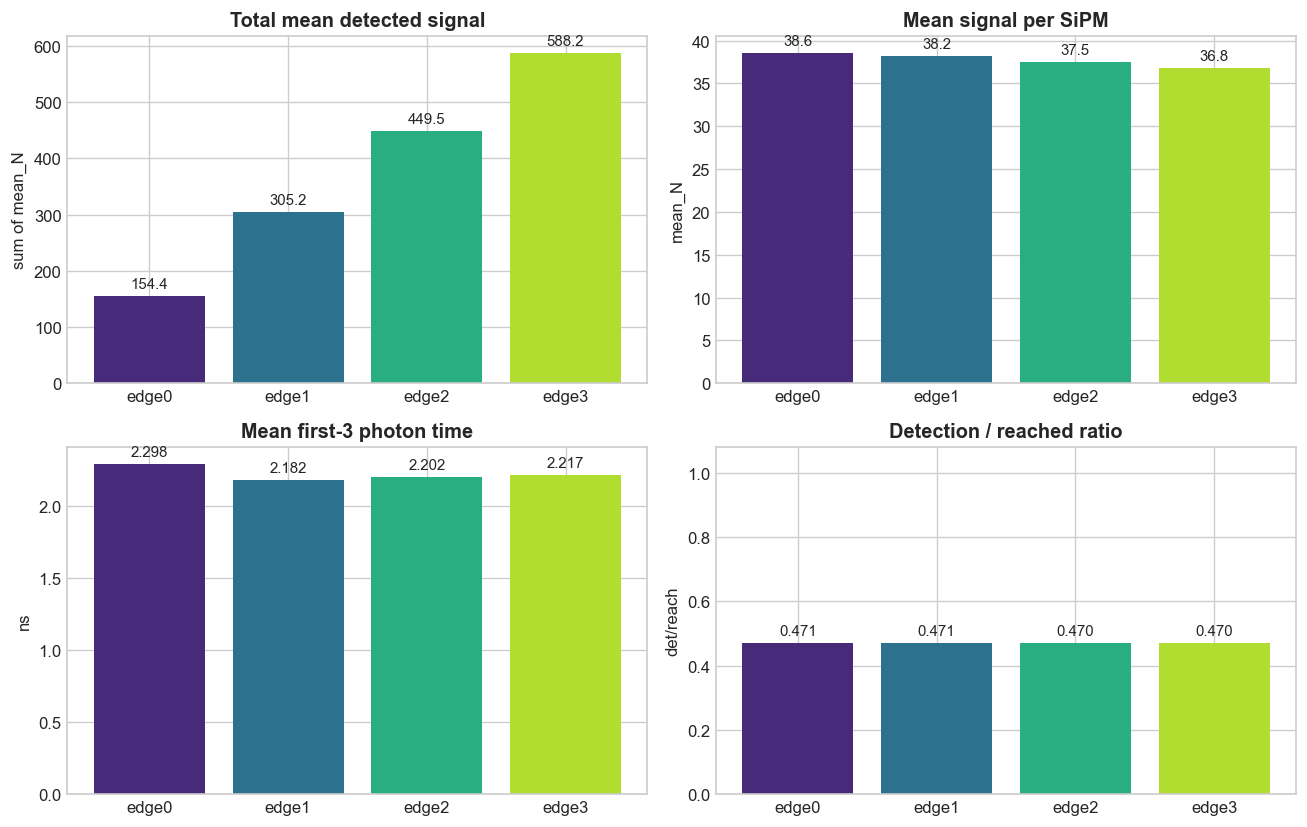

In [55]:
overview = (
    signal.groupby(['setup','edge','n_sipm'],as_index=False)
    .agg(
        total_mean_N=('mean_N','sum'),
        mean_N_per_sipm=('mean_N','mean'),
        mean_hit_probability=('P(N>=1)','mean'),
        mean_first3_ns=('mean_first3_ns','mean'),
        min_first3_ns=('mean_first3_ns','min'),
        max_first3_ns=('mean_first3_ns','max'),
        mean_det_over_reach=('det/reach','mean'),
    )
    .sort_values('edge')
)
display(overview)

fig,axes=plt.subplots(2,2,figsize=(11,7))
x=np.arange(len(overview))
bar_colors=[colors[s] for s in overview['setup']]

plots=[
    (axes[0,0],'total_mean_N','Total mean detected signal','sum of mean_N','.1f'),
    (axes[0,1],'mean_N_per_sipm','Mean signal per SiPM','mean_N','.1f'),
    (axes[1,0],'mean_first3_ns','Mean first-3 photon time','ns','.3f'),
    (axes[1,1],'mean_det_over_reach','Detection / reached ratio','det/reach','.3f'),
]

for ax,col,title,ylabel,fmt in plots:
    b=ax.bar(x,overview[col],color=bar_colors)
    ax.set(title=title,ylabel=ylabel)
    ax.bar_label(b,fmt=f'%{fmt}',padding=3,fontsize=9)
    ax.set_xticks(x,overview['setup'])

axes[1,1].set_ylim(0,1.08)

finish_figure(fig,'01_setup_signal_overview.png')

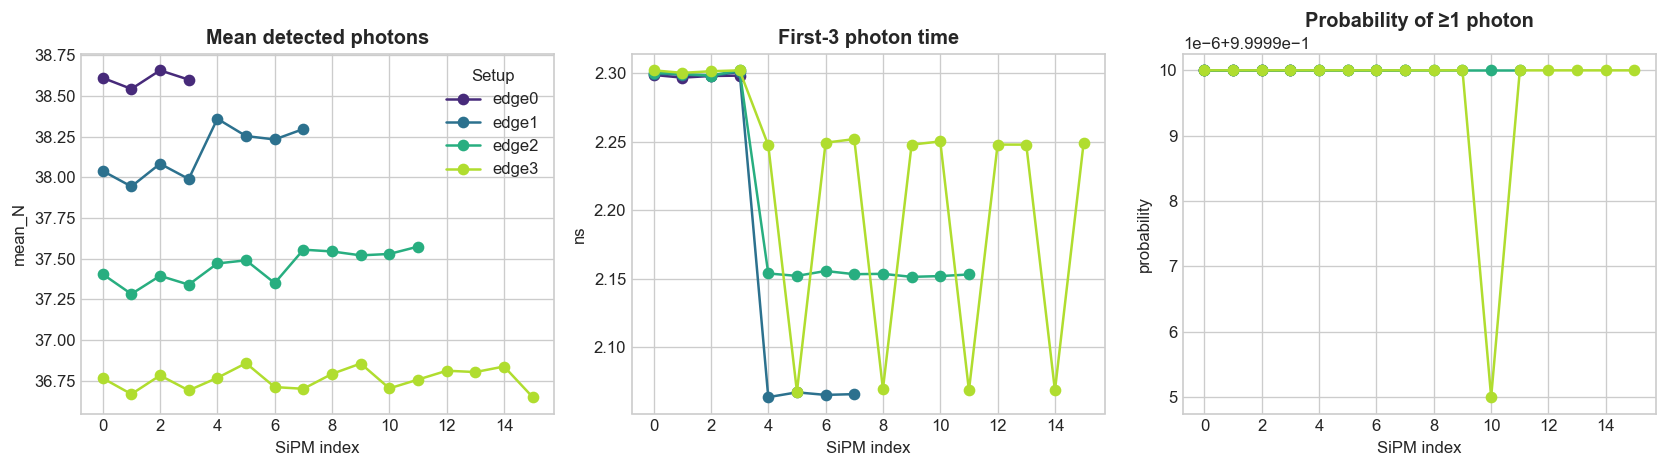

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = [
    ('mean_N', 'Mean detected photons', 'mean_N'),
    ('mean_first3_ns', 'First-3 photon time', 'ns'),
    ('P(N>=1)', 'Probability of ≥1 photon', 'probability'),
]
for ax, (metric, title, ylabel) in zip(axes, metrics):
    for setup in setup_order:
        part = signal[signal['setup'] == setup].sort_values('SiPM')
        ax.plot(part['SiPM'], part[metric], marker='o', label=setup, color=colors[setup])
    ax.set(title=title, xlabel='SiPM index', ylabel=ylabel)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(title='Setup')
finish_figure(fig, '02_per_sipm_signals.png')

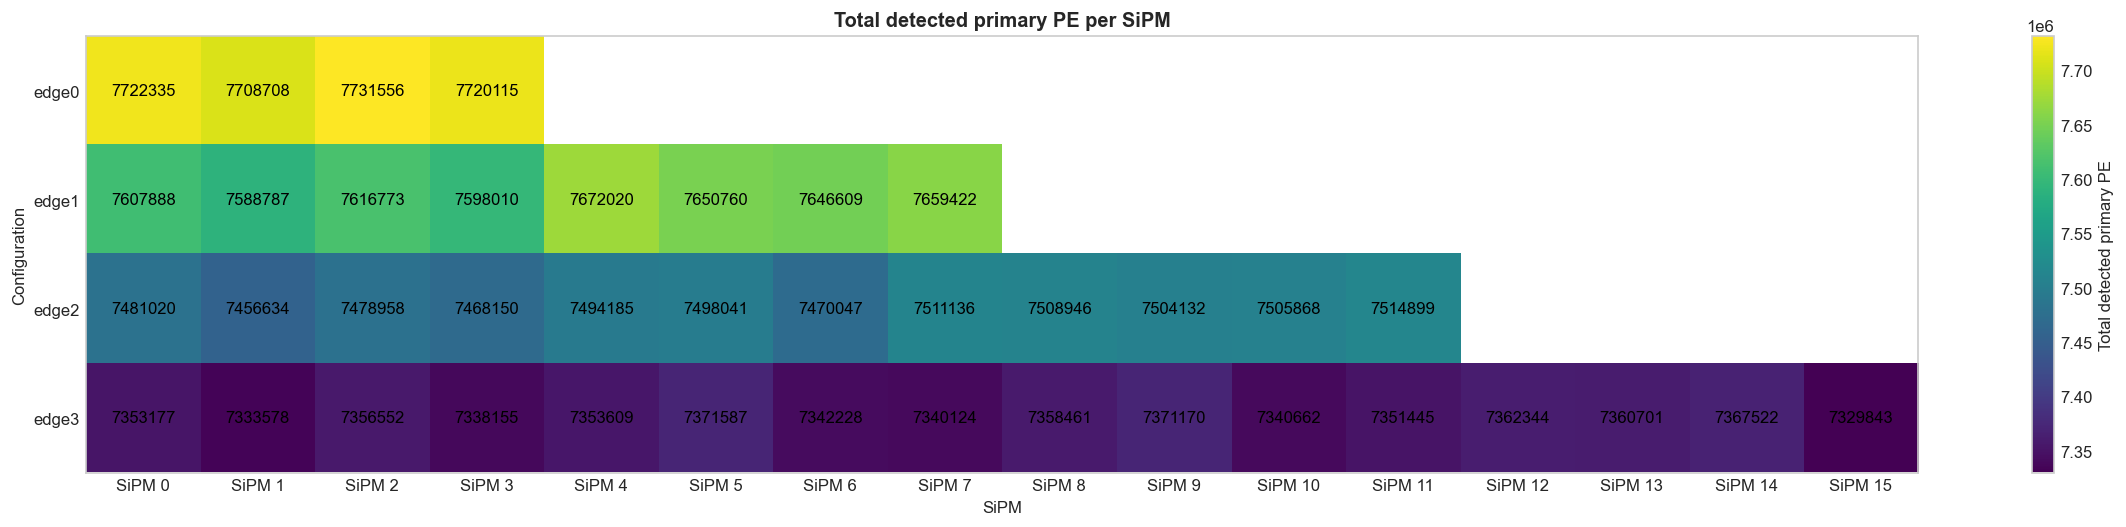

In [57]:
Nevt = 200000   # replace with your actual number of events
signal['total_N'] = signal['mean_N'] * Nevt

heat = (
    signal.pivot(index='setup',columns='SiPM',values='total_N')
    .reindex(setup_order)
)

fig,ax=plt.subplots(figsize=(20,4.5))
m=np.ma.masked_invalid(heat.to_numpy())
im=ax.imshow(m,aspect='auto',cmap='viridis')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v=heat.iloc[i,j]
        if pd.notna(v):
            ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                    color='white' if v<2050000 else 'black',
                    fontsize=10)

ax.set_xticks(range(heat.shape[1]),[f'SiPM {i}' for i in heat.columns])
ax.set_yticks(range(heat.shape[0]),heat.index)
ax.set(
    xlabel='SiPM',
    ylabel='Configuration',
    title='Total detected primary PE per SiPM'
)
ax.grid(False)

fig.colorbar(im,ax=ax,label='Total detected primary PE')
finish_figure(fig,'07_total_detected_per_SiPM.png')

## 3. Effective SiPM layouts

All panels use the same scale and equal aspect ratio, so their inferred spatial coverage can be compared directly. Labels are SiPM indices.

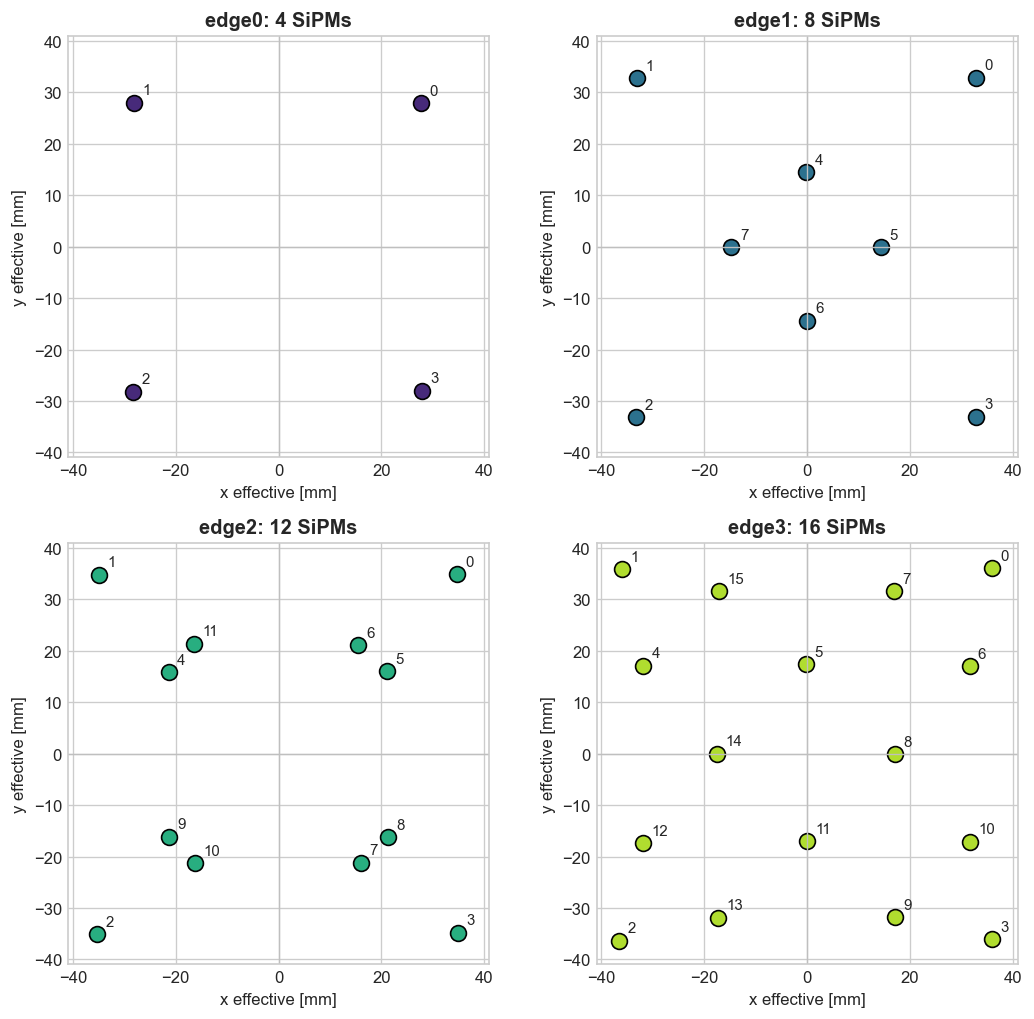

In [58]:
ncols = min(2, len(setup_order))
nrows = int(np.ceil(len(setup_order) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.3 * nrows), squeeze=False)
limit = 1.12 * np.abs(positions[['x_eff_mm', 'y_eff_mm']].to_numpy()).max()

for ax, setup in zip(axes.flat, setup_order):
    part = positions[positions['setup'] == setup].sort_values('SiPM')
    ax.scatter(part['x_eff_mm'], part['y_eff_mm'], s=90, color=colors[setup], edgecolor='black')
    for row in part.itertuples():
        ax.annotate(str(row.SiPM), (row.x_eff_mm, row.y_eff_mm),
                    xytext=(5, 5), textcoords='offset points', fontsize=9)
    ax.axhline(0, color='0.75', lw=0.8)
    ax.axvline(0, color='0.75', lw=0.8)
    ax.set(title=f'{setup}: {len(part)} SiPMs', xlabel='x effective [mm]', ylabel='y effective [mm]',
           xlim=(-limit, limit), ylim=(-limit, limit), aspect='equal')
for ax in axes.flat[len(setup_order):]:
    ax.axis('off')
finish_figure(fig, '03_effective_sipm_layouts.png')

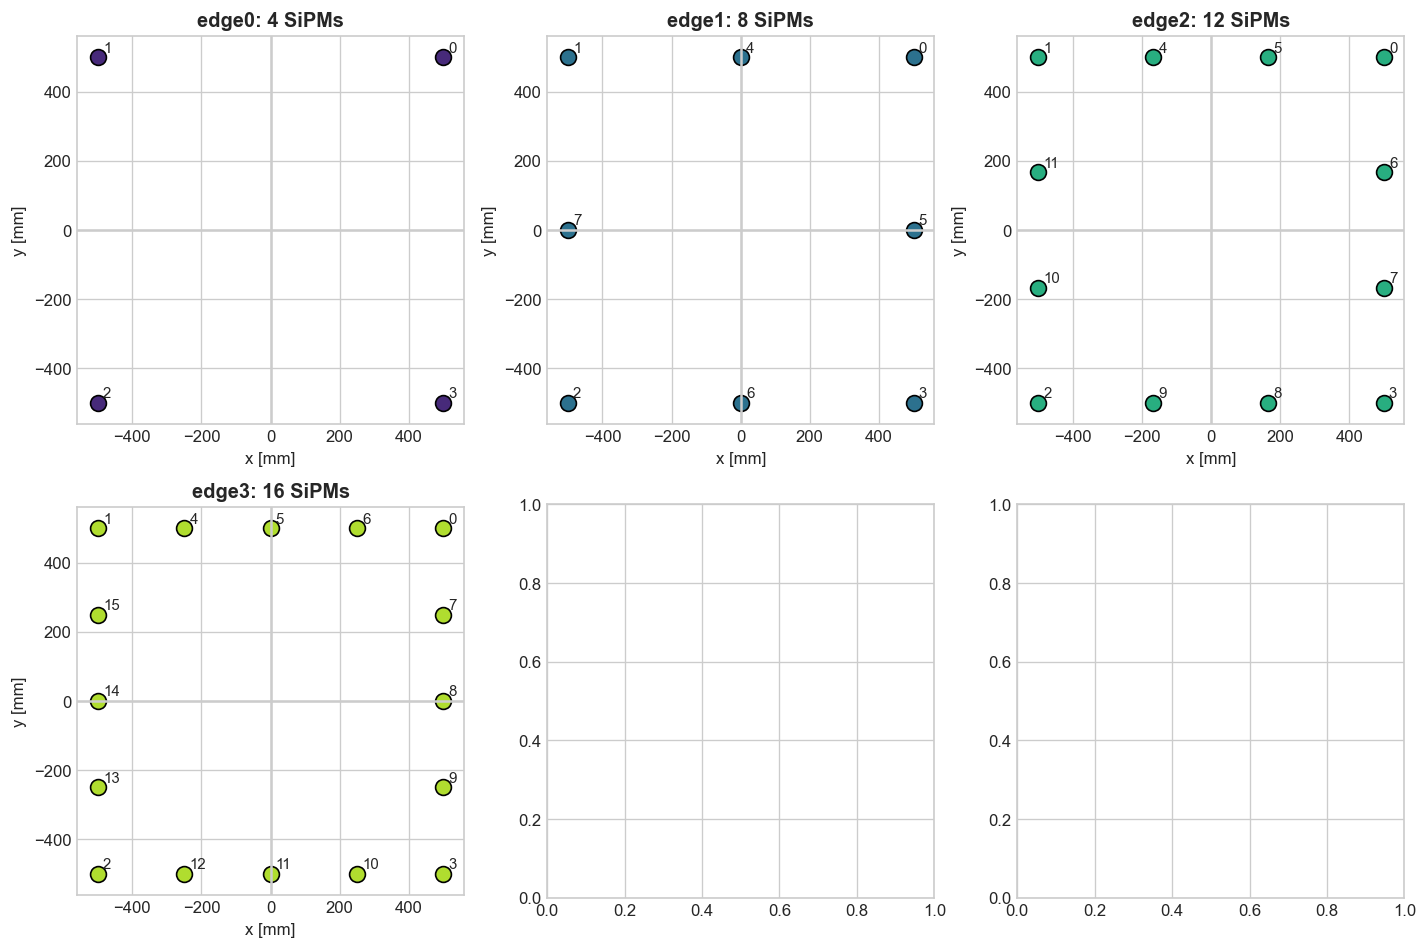

In [59]:
L=500

def pos(setup):
    N=int(setup[-1]); u=np.linspace(-L,L,N+2)[1:-1]
    p=[(0,L,L),(1,-L,L),(2,-L,-L),(3,L,-L)]
    p += [(4+i,u[i],L) for i in range(N)]
    p += [(4+N+i,L,-u[i]) for i in range(N)]
    p += [(4+2*N+i,-u[i],-L) for i in range(N)]
    p += [(4+3*N+i,-L,u[i]) for i in range(N)]
    return p

fig,axes=plt.subplots(2,3,figsize=(12,8))

for ax,s in zip(axes.flat,setup_order):
    p=pos(s); ids,x,y=zip(*p)
    ax.scatter(x,y,s=90,color=colors[s],edgecolor='k')
    for i,X,Y in p: ax.text(X+15,Y+15,str(i),fontsize=9)
    ax.axhline(0,color='.8'); ax.axvline(0,color='.8')
    ax.set(title=f'{s}: {len(p)} SiPMs',xlabel='x [mm]',ylabel='y [mm]',
           xlim=(-560,560),ylim=(-560,560),aspect='equal')

finish_figure(fig,'03_truth_sipm_layouts.png')

## 4. Reconstruction-resolution comparison

R68 is the primary ranking metric here. The method names are normalized so the setup-specific `4/8/12-SiPM effective COG` rows compare as one method.

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


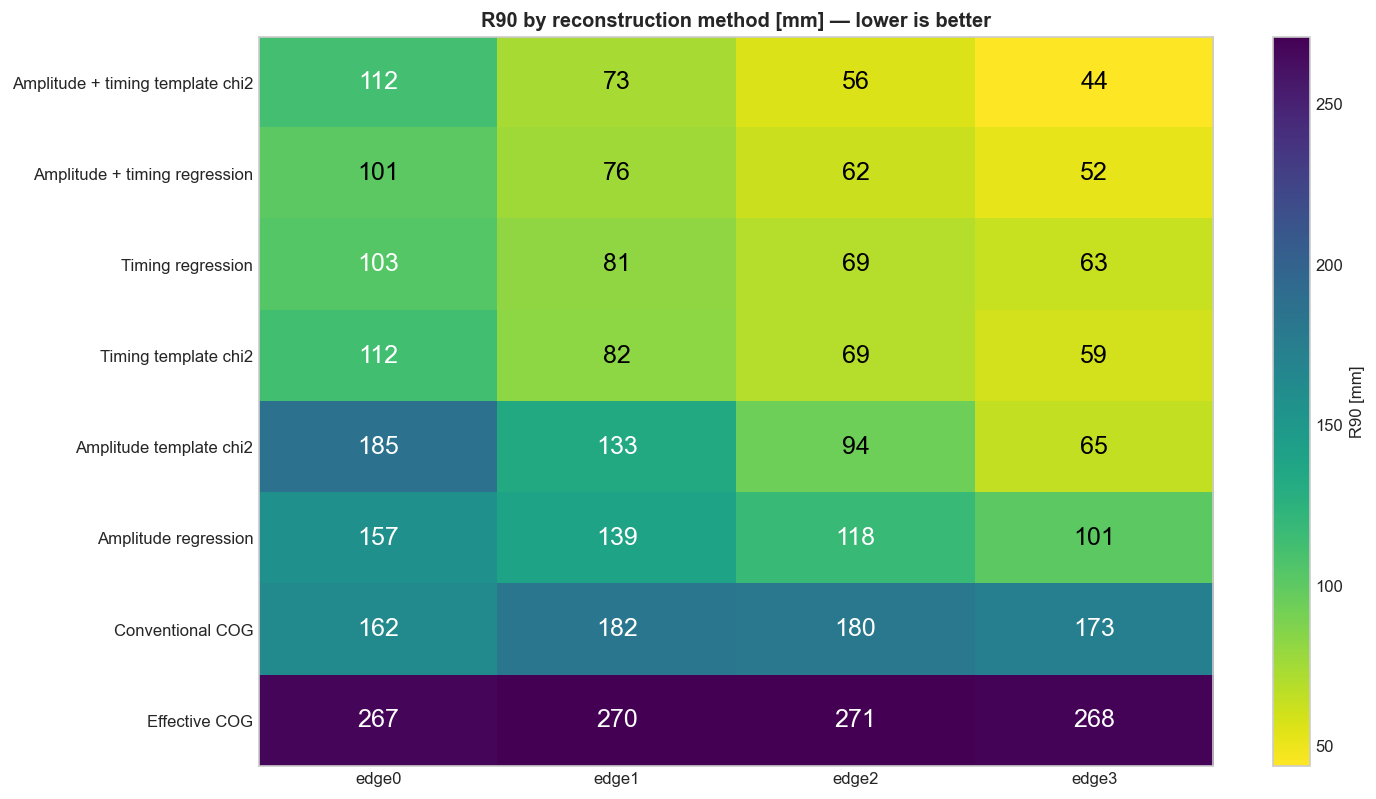

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


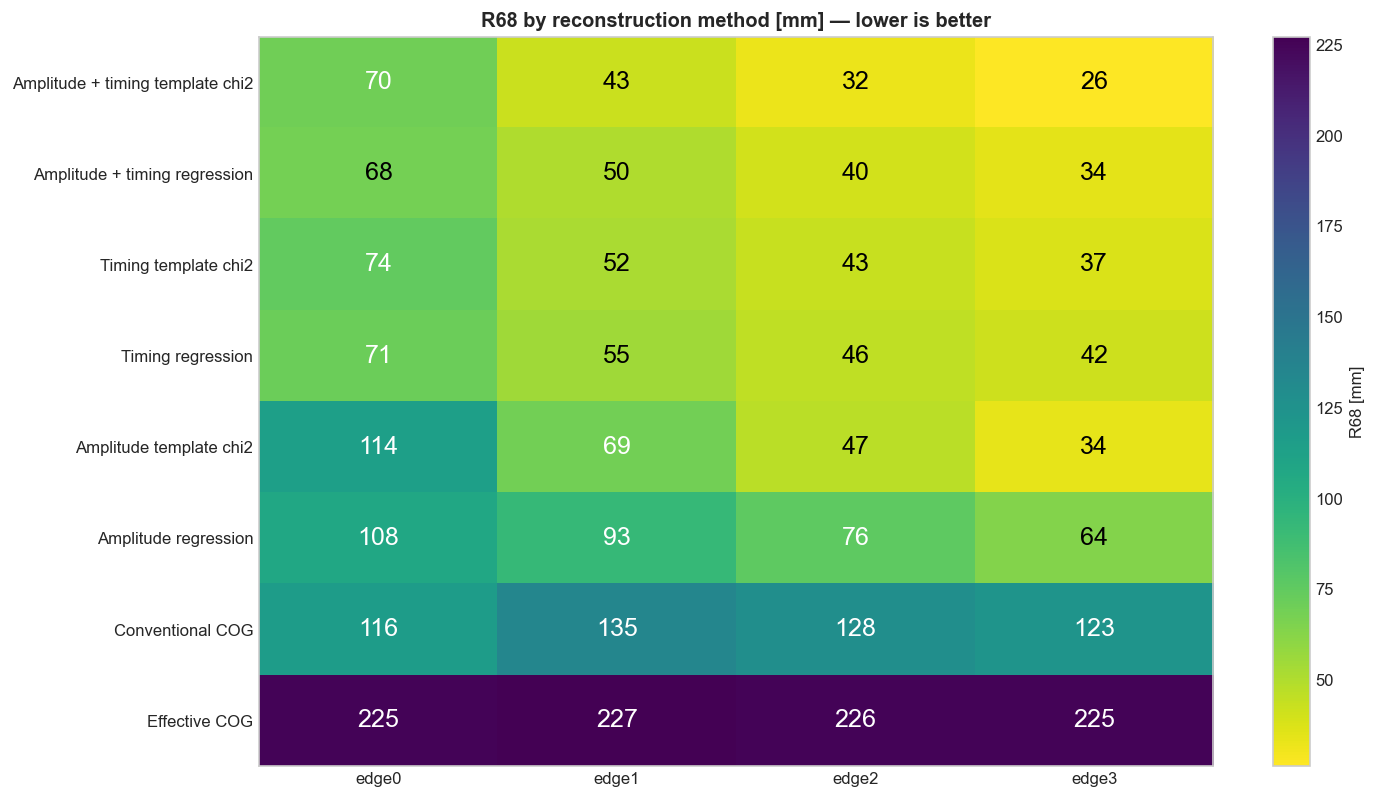

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


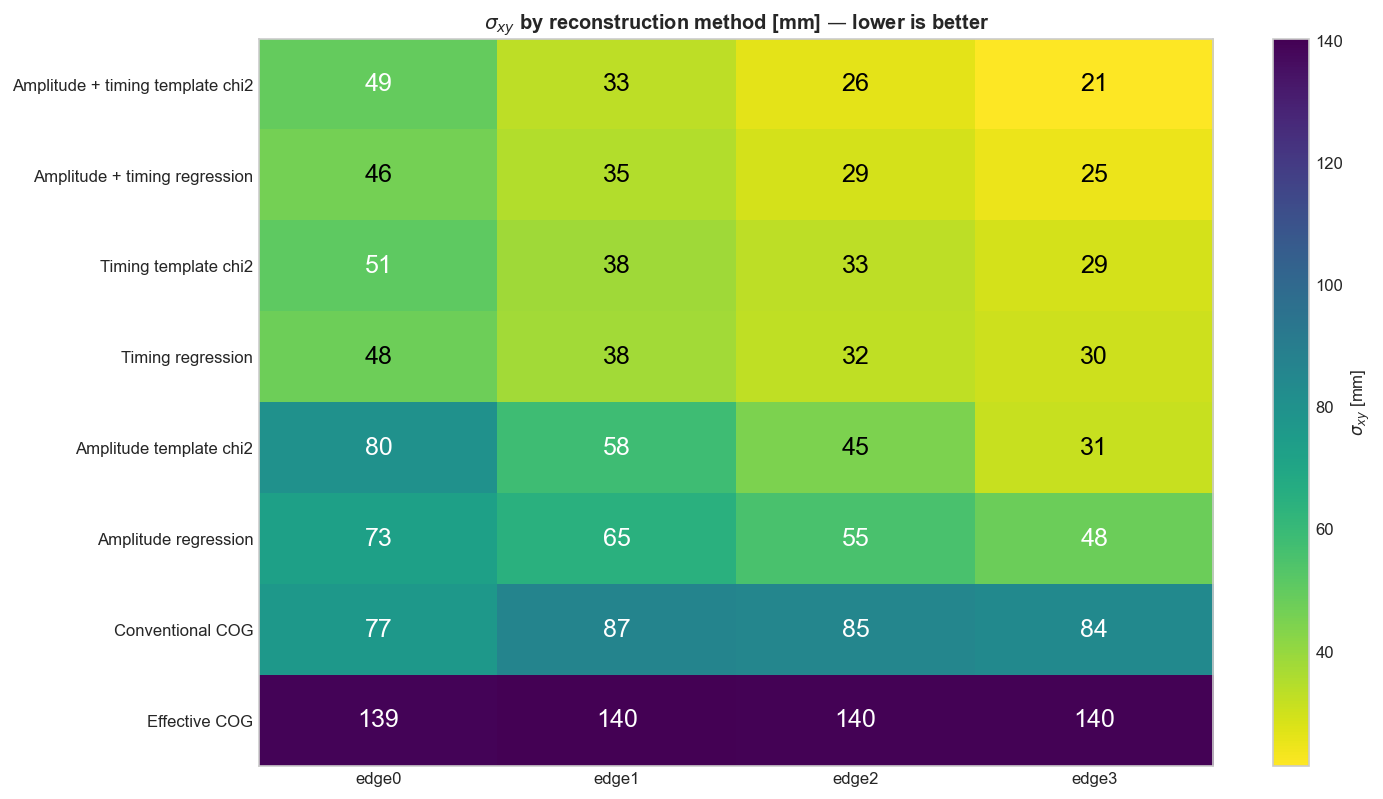

In [60]:
method_order_R90 = resolution.groupby('method')['R90_mm'].mean().sort_values().index.tolist()
# --- R90 ---
heat = resolution.pivot(index='method',columns='setup',values='R90_mm').reindex(
    index=method_order_R90,columns=setup_order)

fig,ax=plt.subplots(figsize=(1.7*len(setup_order)+5.5,0.62*len(heat)+1.8))
masked=np.ma.masked_invalid(heat.to_numpy())
im=ax.imshow(masked,cmap='viridis_r',aspect='auto')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v=heat.iloc[i,j]
        if pd.notna(v):
            ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                    color='white' if v>np.nanmedian(masked) else 'black',fontsize=15)
ax.grid(False)
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_title('R90 by reconstruction method [mm] — lower is better')
fig.colorbar(im,ax=ax,label='R90 [mm]')
finish_figure(fig,'04_r90_method_heatmap.png')

method_order_R68 = resolution.groupby('method')['R68_mm'].mean().sort_values().index.tolist()
# --- R68 ---
heat = resolution.pivot(index='method',columns='setup',values='R68_mm').reindex(
    index=method_order_R68,columns=setup_order)

fig,ax=plt.subplots(figsize=(1.7*len(setup_order)+5.5,0.62*len(heat)+1.8))
masked=np.ma.masked_invalid(heat.to_numpy())
im=ax.imshow(masked,cmap='viridis_r',aspect='auto')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v=heat.iloc[i,j]
        if pd.notna(v):
            ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                    color='white' if v>np.nanmedian(masked) else 'black',fontsize=15)
ax.grid(False)
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_title('R68 by reconstruction method [mm] — lower is better')
fig.colorbar(im,ax=ax,label='R68 [mm]')
finish_figure(fig,'04_r68_method_heatmap.png')


# --- sigma_xy ---
heat = resolution.pivot(index='method',columns='setup',values='sigma_xy_mm').reindex(
    index=method_order_R68,columns=setup_order)

fig,ax=plt.subplots(figsize=(1.7*len(setup_order)+5.5,0.62*len(heat)+1.8))
masked=np.ma.masked_invalid(heat.to_numpy())
im=ax.imshow(masked,cmap='viridis_r',aspect='auto')

for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v=heat.iloc[i,j]
        if pd.notna(v):
            ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                    color='white' if v>np.nanmedian(masked) else 'black',fontsize=15)
ax.grid(False)
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_title(r'$\sigma_{xy}$ by reconstruction method [mm] — lower is better')
fig.colorbar(im,ax=ax,label=r'$\sigma_{xy}$ [mm]')
finish_figure(fig,'04_sigmaXY_method_heatmap.png')

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


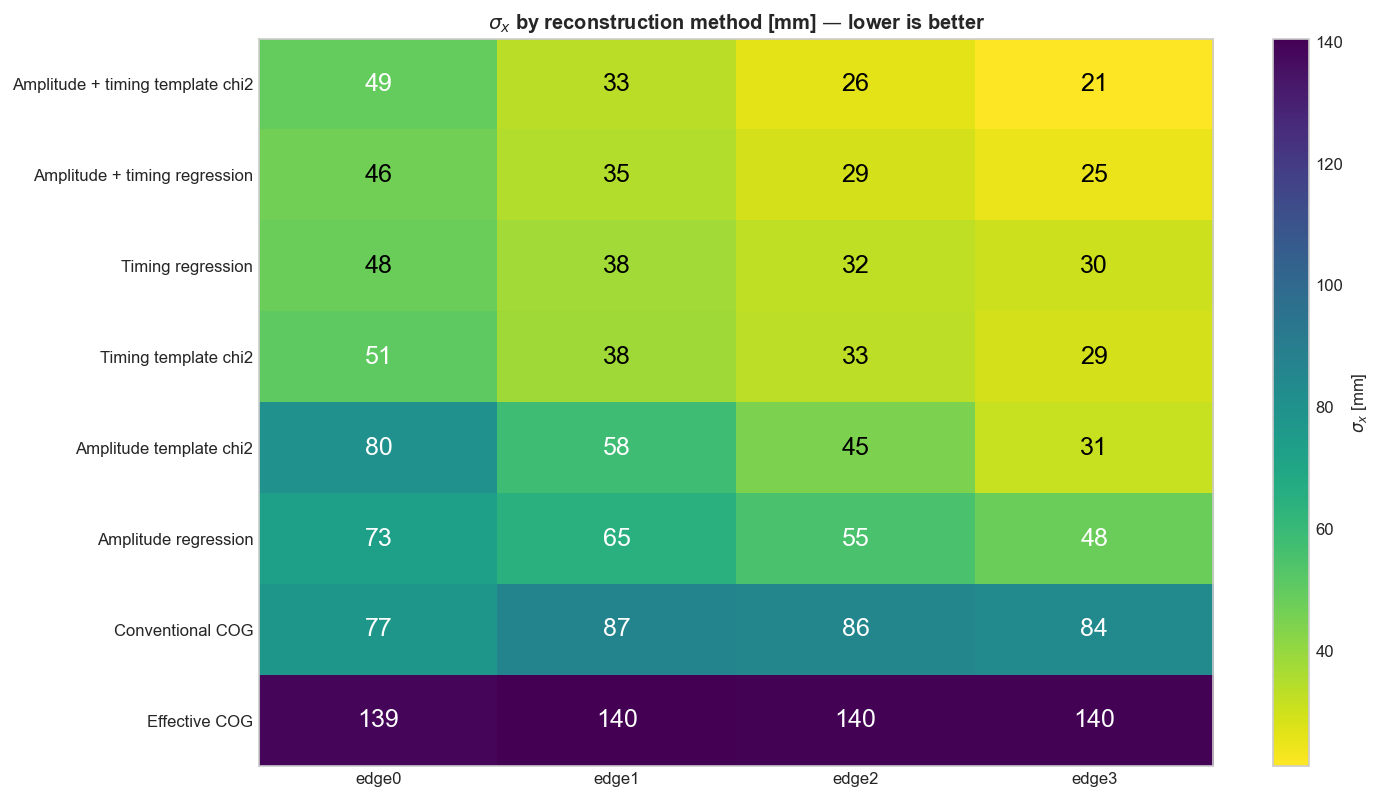

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


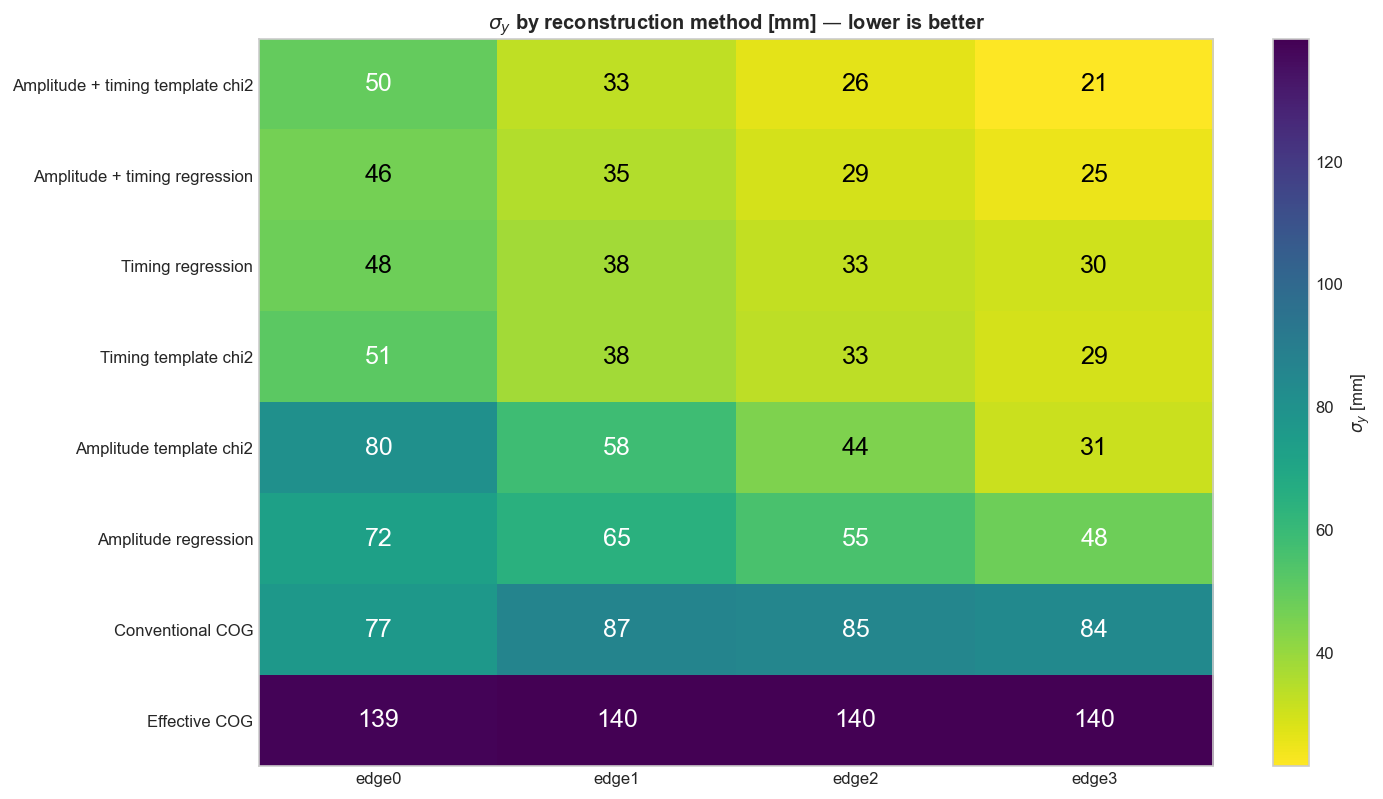

In [61]:
# --- SigmaX / SigmaY heatmaps ---
for col,label,fname in [
    ('sigma_x_mm',r'$\sigma_x$','04_sigmaX_method_heatmap.png'),
    ('sigma_y_mm',r'$\sigma_y$','04_sigmaY_method_heatmap.png'),
]:
    order=resolution.groupby('method')[col].mean().sort_values().index
    heat=resolution.pivot(index='method',columns='setup',values=col).reindex(
        index=order,columns=setup_order)

    fig,ax=plt.subplots(figsize=(1.7*len(setup_order)+5.5,0.62*len(heat)+1.8))
    m=np.ma.masked_invalid(heat.to_numpy())
    im=ax.imshow(m,cmap='viridis_r',aspect='auto')

    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v=heat.iloc[i,j]
            if pd.notna(v):
                ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                        color='white' if v>np.nanmedian(m) else 'black',fontsize=15)

    ax.set_xticks(range(len(heat.columns)),heat.columns)
    ax.set_yticks(range(len(heat.index)),heat.index)
    ax.set_title(f'{label} by reconstruction method [mm] — lower is better')
    ax.grid(False)
    fig.colorbar(im,ax=ax,label=f'{label} [mm]')
    finish_figure(fig,fname)

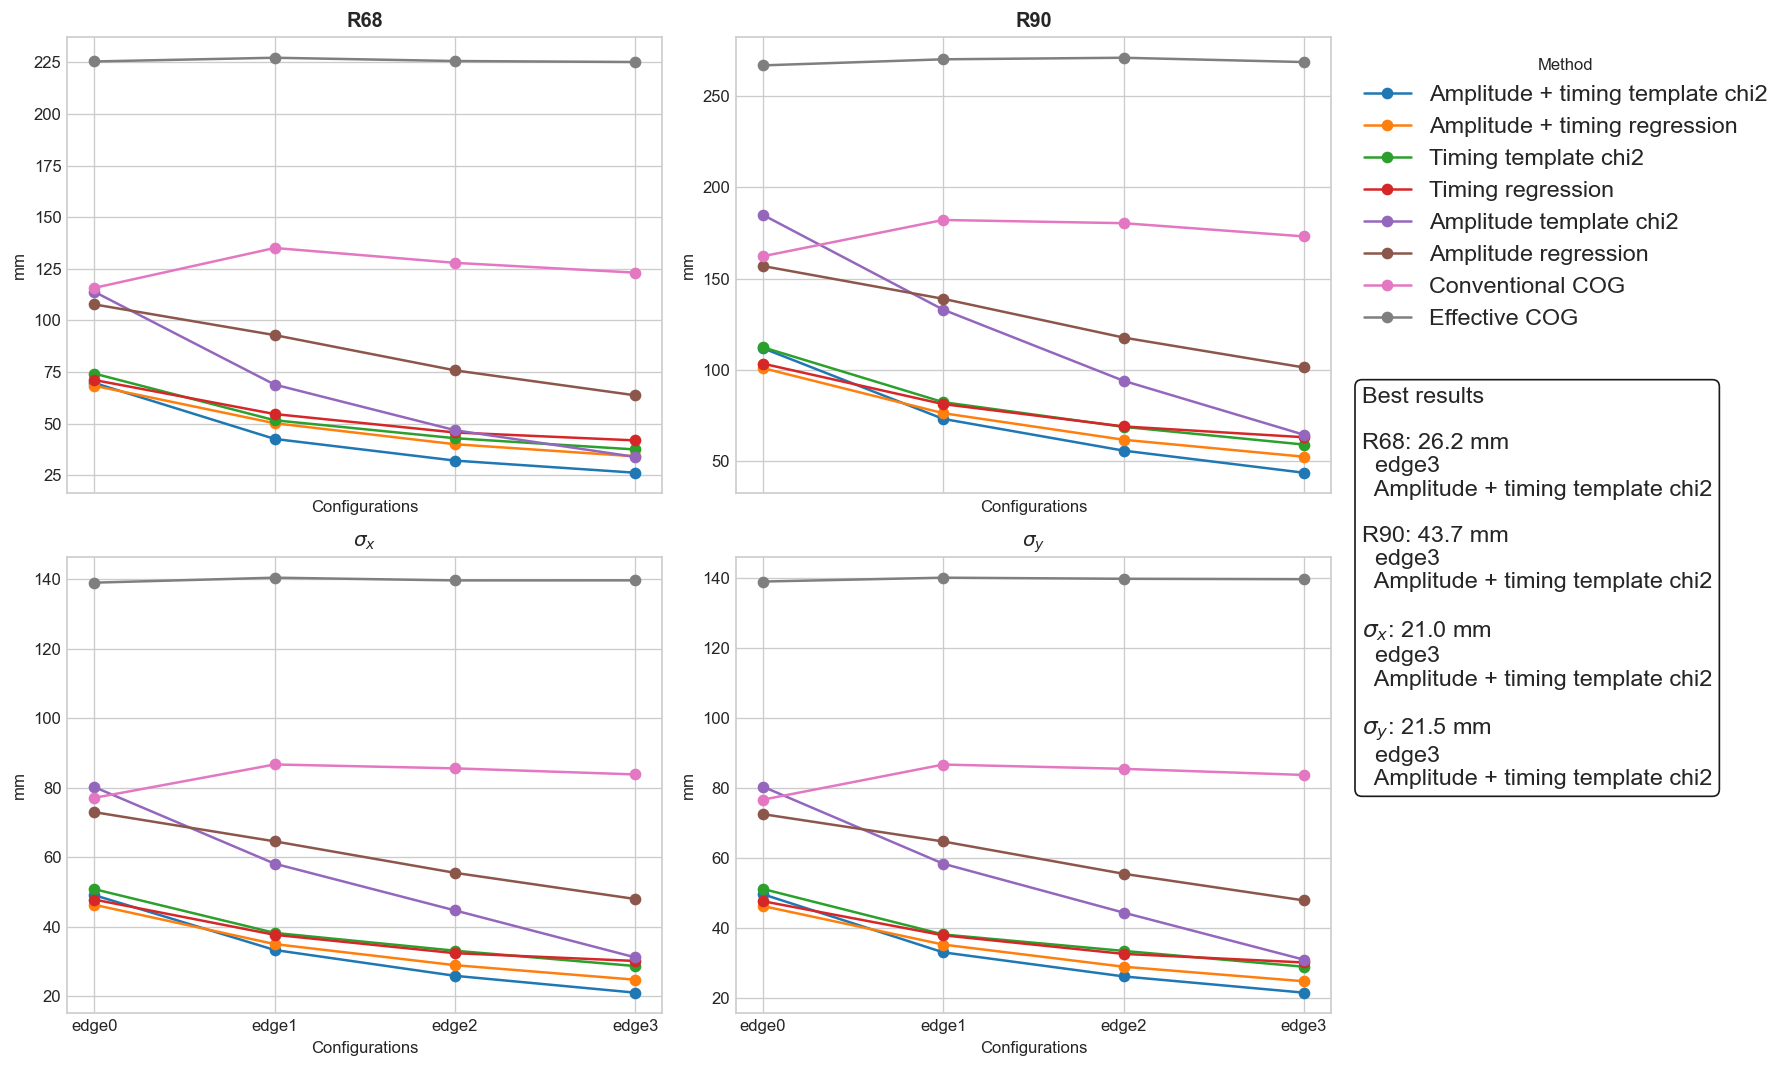

In [62]:
fig,axes=plt.subplots(2,2,figsize=(15,9),sharex=True)
metrics=['R68_mm','R90_mm','sigma_x_mm','sigma_y_mm']
titles=['R68','R90',r'$\sigma_x$',r'$\sigma_y$']

best_txt=[]

for ax,metric,title in zip(axes.flat,metrics,titles):
    pivot=resolution.pivot(index='setup',columns='method',values=metric).reindex(setup_order)

    for method in method_order_R68:
        if method in pivot:
            ax.plot(setup_order,pivot[method],marker='o',label=method)

    row=resolution.loc[resolution[metric].idxmin()]
    best_txt.append(
        f"{title}: {row[metric]:.1f} mm\n"
        f"  {row['setup']}\n"
        f"  {row['method']}"
    )

    ax.set(title=title,xlabel='Configurations',ylabel='mm')

axes[0,1].legend(title='Method',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=14)

fig.subplots_adjust(right=.78)
fig.text(
    .76,.45,
    "Best results\n\n"+"\n\n".join(best_txt),
    va='center',ha='left',fontsize=14,
    bbox=dict(boxstyle='round',fc='white',alpha=.9)
)

finish_figure(fig,'05_resolution_trends.png')

## 5. Existing spatial maps and CDFs

These panels reuse the analysis images without altering them. Change `IMAGE_TO_COMPARE` to any common output name, for example `07_best_mean_radial_error_map.png`, `08_best_R68_map.png`, or `10_radial_error_CDF.png`.

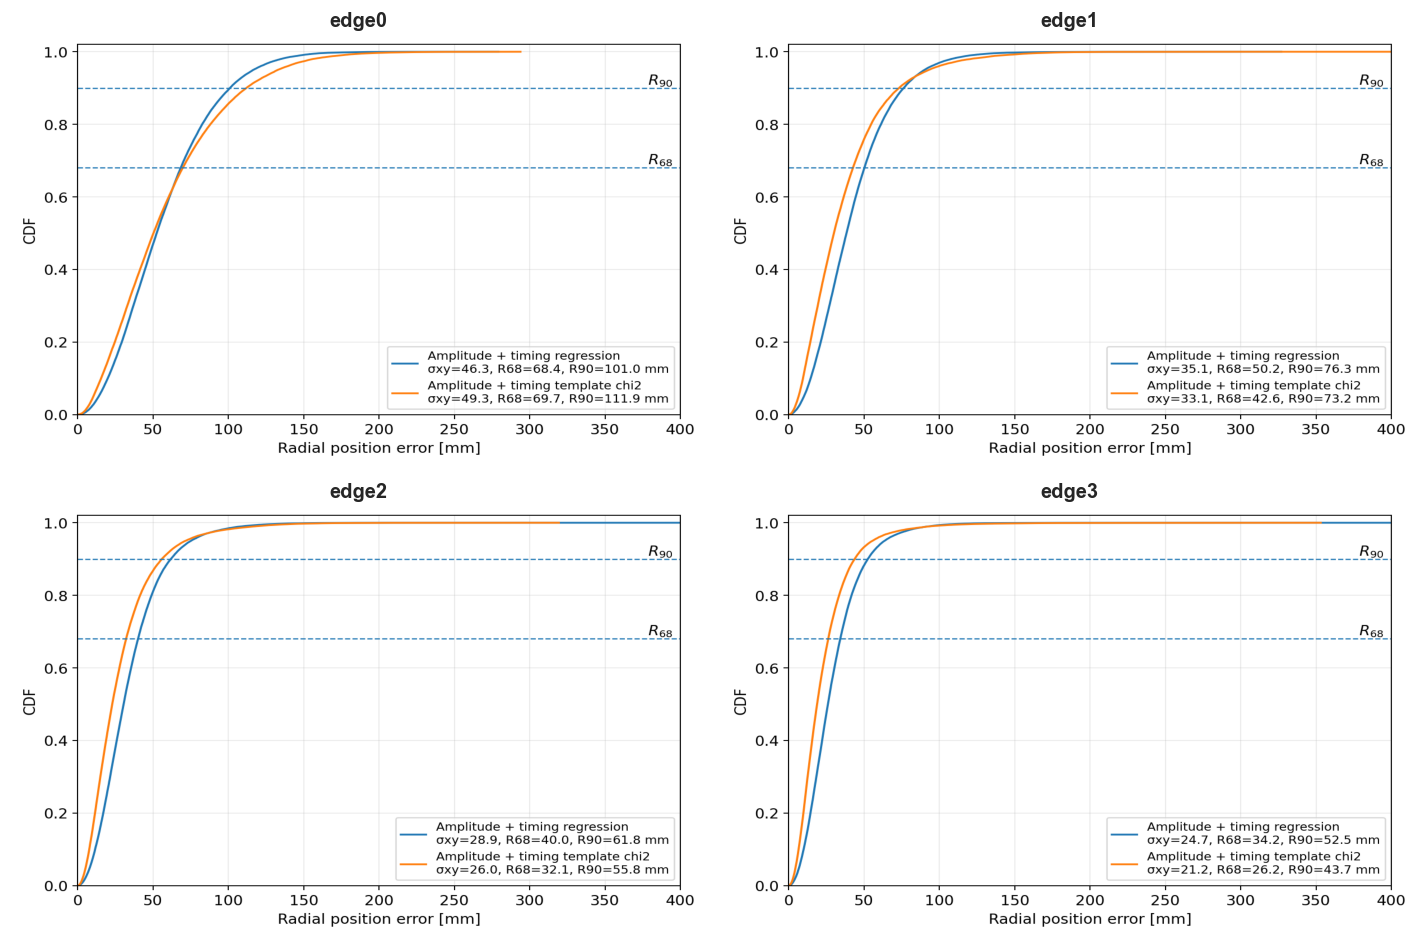

In [68]:
IMAGE_TO_COMPARE = '10_radial_error_CDF.png'
available = [(f'edge{edge_number(folder)}', folder / IMAGE_TO_COMPARE) for folder in analysis_dirs]
available = [(setup, path) for setup, path in available if path.exists()]

if available:
    # fig, axes = plt.subplots(2, 3, figsize=(15,8), squeeze=False)
    fig, axes = plt.subplots(2, 2, figsize=(12,8), squeeze=False)
    for ax, (setup, path) in zip(axes.flat, available):
        ax.imshow(plt.imread(path), aspect='auto')
        ax.set_title(setup)
        ax.axis('off')
    finish_figure(fig, f'06_compare_{Path(IMAGE_TO_COMPARE).stem}.png')
else:
    print(f'No setup contains {IMAGE_TO_COMPARE}')

/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)
/Users/chiu-ping/.pipvenv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:870: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


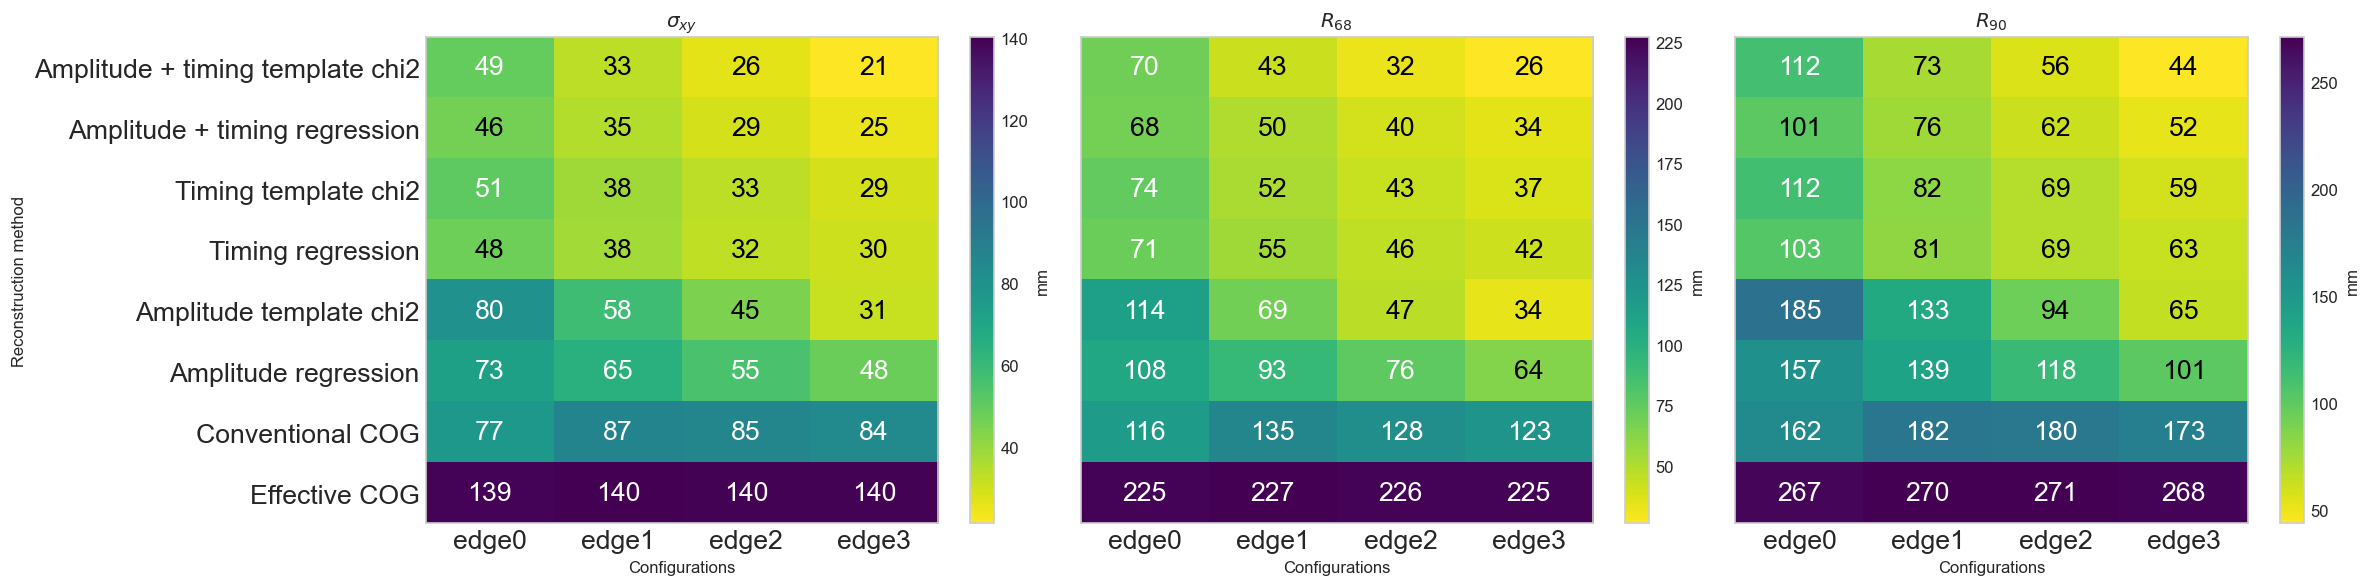

In [64]:
metrics=[('sigma_xy_mm',r'$\sigma_{xy}$'),
         ('R68_mm',r'$R_{68}$'),
         ('R90_mm',r'$R_{90}$')]

fig,axes=plt.subplots(1,3,figsize=(20,5),sharey=True)

for ax,(col,title) in zip(axes,metrics):
    h=resolution.pivot(index='method',columns='setup',values=col).reindex(
        index=method_order_R68,columns=setup_order)
    m=np.ma.masked_invalid(h.to_numpy())
    im=ax.imshow(m,cmap='viridis_r',aspect='auto')

    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            v=h.iloc[i,j]
            if pd.notna(v):
                ax.text(j,i,f'{v:.0f}',ha='center',va='center',
                        color='white' if v>np.nanmedian(m) else 'black',fontsize=16)

    ax.set_xticks(range(len(setup_order)),setup_order,fontsize=16)
    ax.set_yticks(range(len(method_order_R68)),method_order_R68,fontsize=16)
    ax.set(title=title,xlabel='Configurations')
    ax.grid(False)
    fig.colorbar(im,ax=ax,label='mm')

axes[0].set_ylabel('Reconstruction method')
finish_figure(fig,'06_all_resolution_heatmaps.png')

## 6. Automated takeaways and timing sanity check

In [65]:
best = (resolution.loc[resolution.groupby('setup')['sigma_xy_mm'].idxmin()]
        .set_index('setup').reindex(setup_order).reset_index())
lines = []

for row in best.itertuples():
    lines.append(
        f'- **{row.setup} ({row.n_sipm} SiPMs):** best '
        f'$\\sigma_{{xy}}$ = {row.sigma_xy_mm:.1f} mm '
        f'with {row.method_original}; '
        f'R68 = {row.R68_mm:.1f} mm, R90 = {row.R90_mm:.1f} mm.'
    )

for previous, current in zip(best.itertuples(), best.iloc[1:].itertuples()):
    gain = 100*(previous.sigma_xy_mm-current.sigma_xy_mm)/previous.sigma_xy_mm
    lines.append(
        f'- Best $\\sigma_{{xy}}$ improves by **{gain:.1f}%** '
        f'from {previous.setup} to {current.setup}.'
    )

timing = overview.set_index('setup')['mean_first3_ns']
if len(timing)>1 and timing.max()/timing.min()>2:
    slow = timing.idxmax()
    lines.append(
        f'- ⚠️ **Timing check:** {slow} has mean first-3 time '
        f'{timing[slow]:.2f} ns, more than twice the smallest setup mean '
        f'({timing.min():.2f} ns).'
    )

display(Markdown('\n'.join(lines)))

- **edge0 (4 SiPMs):** best $\sigma_{xy}$ = 46.3 mm with Amplitude + timing regression; R68 = 68.4 mm, R90 = 101.0 mm.
- **edge1 (8 SiPMs):** best $\sigma_{xy}$ = 33.1 mm with Amplitude + timing template chi2; R68 = 42.6 mm, R90 = 73.2 mm.
- **edge2 (12 SiPMs):** best $\sigma_{xy}$ = 26.0 mm with Amplitude + timing template chi2; R68 = 32.1 mm, R90 = 55.8 mm.
- **edge3 (16 SiPMs):** best $\sigma_{xy}$ = 21.2 mm with Amplitude + timing template chi2; R68 = 26.2 mm, R90 = 43.7 mm.
- Best $\sigma_{xy}$ improves by **28.4%** from edge0 to edge1.
- Best $\sigma_{xy}$ improves by **21.6%** from edge1 to edge2.
- Best $\sigma_{xy}$ improves by **18.3%** from edge2 to edge3.

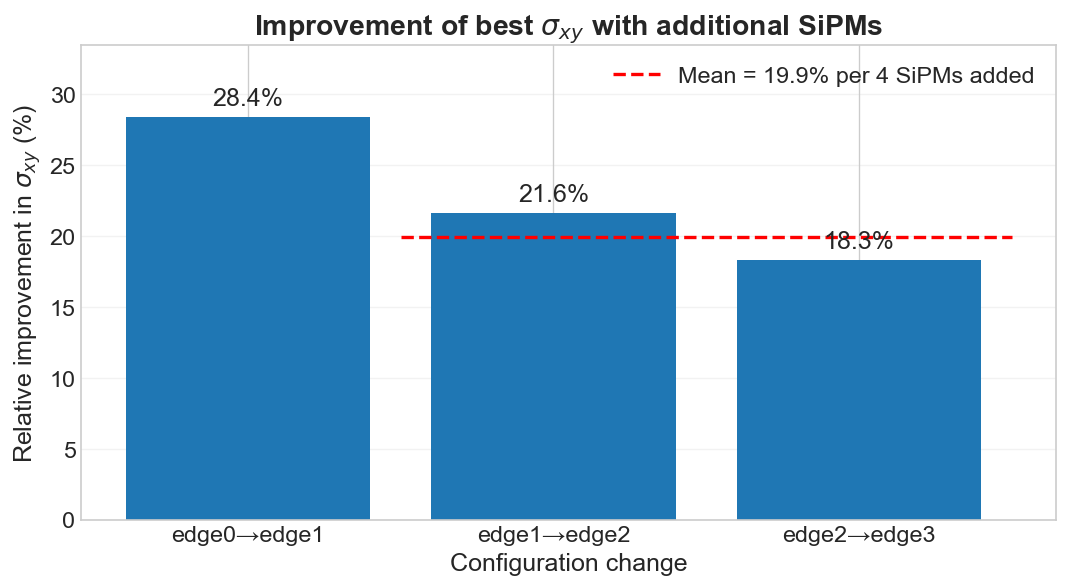

In [66]:
# Relative improvement of best sigma_xy
prev = best.sigma_xy_mm.to_numpy()[:-1]
curr = best.sigma_xy_mm.to_numpy()[1:]
gain = 100*(prev-curr)/prev
labels = [f'{a}→{b}' for a,b in zip(best.setup[:-1],best.setup[1:])]

fig,ax=plt.subplots(figsize=(9,5))
bars=ax.bar(labels,gain)

for b,v in zip(bars,gain):
    ax.text(b.get_x()+b.get_width()/2,v+0.5,f'{v:.1f}%',
            ha='center',va='bottom',fontsize=15)

# mean of edge1→edge2 through edge4→edge5
mean_gain = gain[1:].mean()
ax.hlines(mean_gain,
          xmin=0.5, xmax=len(labels)-0.5,
          colors='red', linestyles='--', linewidth=2,
          label=f'Mean = {mean_gain:.1f}% per 4 SiPMs added')

ax.set(xlabel='Configuration change',
       ylabel=r'Relative improvement in $\sigma_{xy}$ (%)',
       title=r'Improvement of best $\sigma_{xy}$ with additional SiPMs')
ax.tick_params(labelsize=14)
ax.xaxis.label.set_size(15)
ax.yaxis.label.set_size(15)
ax.title.set_size(17)
ax.set_ylim(0,1.18*gain.max())
ax.grid(axis='y',alpha=.25)
ax.legend(fontsize=14)

finish_figure(fig,'07_relative_sigmaXY_improvement.png')